<a href="https://colab.research.google.com/github/AkshayaKanagala/Amaravati-International/blob/main/titanic_be10x.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
data = df[["Survived", "Pclass", "Sex", "Age", "Fare"]].copy()
data = data.fillna({"Age": data["Age"].mean()})
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
X = data.drop("Survived", axis=1)
y = data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(accuracy_score(y_test, model.predict(X_test)))      # 0.799


0.7988826815642458


<Axes: xlabel='Sex', ylabel='Survived'>

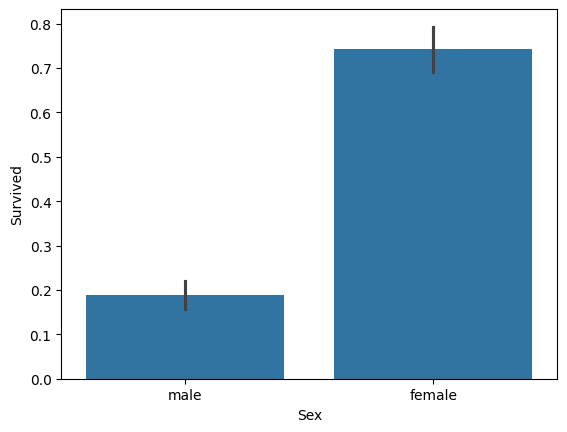

In [ ]:
import seaborn as sns
sns.barplot(data=df, x="Sex", y="Survived")    # try "Pclass", then "Embarked"


<Axes: xlabel='Age', ylabel='Count'>

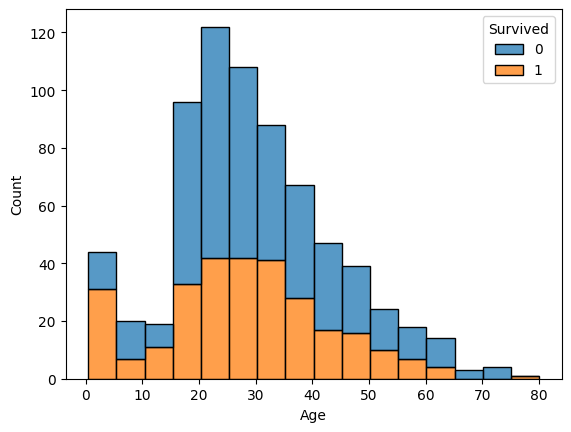

In [ ]:
sns.histplot(data=df, x="Age", hue="Survived", bins=16, multiple="stack")


<Axes: xlabel='Survived', ylabel='Pclass'>

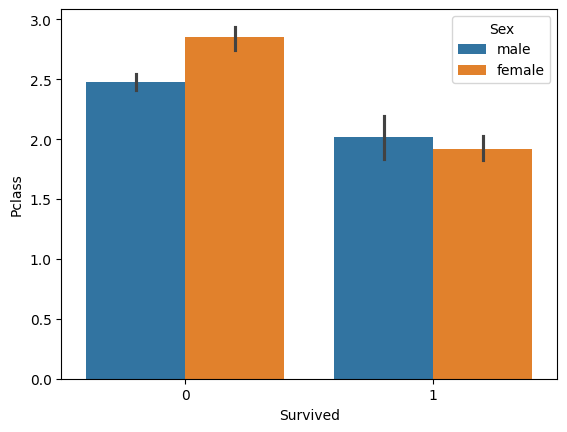

In [ ]:
sns.barplot(data=df, y="Pclass", x="Survived", hue="Sex")

In [ ]:
X2 = X.join(df[["SibSp", "Parch"]])
X2_train, X2_test = train_test_split(X2, test_size=0.2, random_state=42)
model2 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X2_train, y_train)
print(accuracy_score(y_test, model2.predict(X2_test)))
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1          # slide 13
print(df.groupby("FamilySize")["Survived"].mean())

def get_title(name):                                      # slide 14
    return name.split(", ")[1].split(".")[0]              # "Braund, Mr. Owen Harris" → "Mr"

df["Title"] = df["Name"].apply(get_title)
print(df.groupby("Title")["Survived"].mean())


0.7988826815642458


In [ ]:
def get_title(name):                                      # same as slide 14
    return name.split(", ")[1].split(".")[0]

TITLES = {"Mr": 0, "Miss": 1, "Mrs": 2, "Master": 3}       # every other title becomes 4

def prepare(df):
    df = df.fillna({"Age": df["Age"].median(), "Fare": df["Fare"].median()})
    df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["Title"] = df["Name"].apply(get_title).map(TITLES).fillna(4)
    return df[["Pclass", "Sex", "Age", "Fare", "FamilySize", "Title"]]

X = prepare(df)
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X.head())


   Pclass  Sex   Age     Fare  FamilySize  Title
0       3    0  22.0   7.2500           2    0.0
1       1    1  38.0  71.2833           2    2.0
2       3    1  26.0   7.9250           1    1.0
3       1    1  35.0  53.1000           2    2.0
4       3    0  35.0   8.0500           1    0.0


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
accuracy_score(y_test, rf.predict(X_test))


0.8212290502793296

<Axes: >

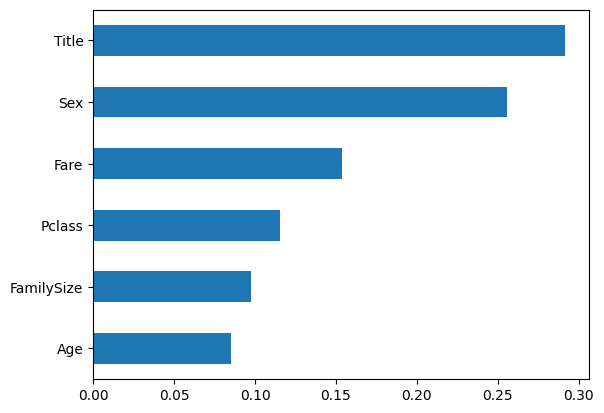

In [ ]:
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind="barh")


In [ ]:
import pandas as pd

try:
    import gradio
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)

def predict(pclass, title, age, fare, family):
    sex = 1 if title in ["Mrs", "Miss"] else 0
    passenger = pd.DataFrame([[pclass, sex, age, fare, family, TITLES[title]]],
                             columns=X.columns)
    chance = float(rf.predict_proba(passenger)[0][1])    # chance of surviving, 0 to 1
    return {"Survived": chance, "Did not survive": 1 - chance}

print(predict(1, "Miss", 17, 100, 2))                    # Rose → Survived 0.97

{'Survived': 0.9700756596274271, 'Did not survive': 0.029924340372572855}


In [ ]:
import gradio as gr

demo = gr.Interface(
    fn=predict,
    inputs=[gr.Radio([1, 2, 3], value=3, label="Class"),
            gr.Radio(["Mr", "Mrs", "Miss", "Master"], value="Mr", label="Title"),
            gr.Slider(1, 80, value=25, label="Age"),
            gr.Slider(0, 300, value=15, label="Fare (£)"),
            gr.Slider(1, 8, value=1, label="Family size")],
    outputs="label",
    title="Would you have survived the Titanic?")
demo.launch(share=True)               # gives you a public link


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://65c6fd222eadca3d1d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import joblib
joblib.dump(rf, "model.pkl")


# ---------- Part 5: What next (slides 29–35) ----------

# Homework (slide 31): put Kaggle's train.csv and test.csv next to this file first
import os
if os.path.exists("train.csv") and os.path.exists("test.csv"):
    train = pd.read_csv("train.csv")
    test = pd.read_csv("test.csv")
    rf.fit(prepare(train), train["Survived"])
    answers = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": rf.predict(prepare(test))})
    answers.to_csv("submission.csv", index=False)        # download this file and submit it
    print("submission.csv is ready")


# ---------- The app (slides 25 and 30) ----------
import gradio as gr

demo = gr.Interface(
    fn=predict,
    inputs=[gr.Radio([1, 2, 3], value=3, label="Class"),
            gr.Radio(["Mr", "Mrs", "Miss", "Master"], value="Mr", label="Title"),
            gr.Slider(1, 80, value=25, label="Age"),
            gr.Slider(0, 300, value=15, label="Fare (£)"),
            gr.Slider(1, 8, value=1, label="Family size")],
    outputs="label",
    title="Would you have survived the Titanic?",
    description="Built by asha  in python session 18 Oct 2026",
    examples=[[1, "Miss", 17, 100, 2], [3, "Mr", 20, 7.5, 1]])
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://649e76e18ba8facf7c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Filter passengers with Age > 45 from our feature matrix X
over_45_mask = X['Age'] > 45
X_over_45 = X[over_45_mask]

# Predict probabilities using our trained Random Forest model
# Column 1 of predict_proba gives the probability of survival (class 1)
probabilities = rf.predict_proba(X_over_45)[:, 1]

# Calculate and display the average probability
average_survival_prob = probabilities.mean()
print(f"Number of passengers older than 45: {len(X_over_45)}")
print(f"Average model-predicted survival probability for Age > 45: {average_survival_prob:.4f}")


Number of passengers older than 45: 103
Average model-predicted survival probability for Age > 45: 0.4164
